# Løsningsforslag – oppgaver uke 42: lineær regresjon

Notatboken løser oppgavene i `oppg_u42.pdf` og hører til Beamer-presentasjonen med samme løsninger.
Python brukes på tre måter:

1. **Kalkulator** – sette tall inn i formler
2. **Sannsynlighetskalkulator** – kritiske verdier og p-verdier fra $t$-fordelingen (`scipy.stats`)
3. **Dataverktøy** – estimere regresjoner direkte fra data (`statsmodels`, `pandas`)

**Data:** Oppgave 2 bruker `data/Datasett_eksamen_h24.csv` og oppgave 4 `data/Datasett_eksamen_h23.csv` (semikolon som skilletegn, komma som desimaltegn).


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

## Nyttige formler

| Størrelse | Formel |
|---|---|
| Testobservator | $t = \dfrac{\hat\beta_j - \beta_{j,0}}{SE(\hat\beta_j)}$, med $n-2$ frihetsgrader (enkel regresjon) |
| Konfidensintervall | $\hat\beta_j \pm t_{\alpha/2,\,n-2}\cdot SE(\hat\beta_j)$ |
| Regresjonens standardfeil | $s_e=\sqrt{\dfrac{\sum e_i^2}{n-2}}$ |
| Standardfeil stigningstall | $SE(\hat\beta_1)=\dfrac{s_e}{\sqrt{S_{xx}}}$, $S_{xx}=\sum(x_i-\bar x)^2$ |
| Prediksjonsintervall | $\hat y_0 \pm t_{\alpha/2,\,n-2}\cdot s_e\sqrt{1+\dfrac1n+\dfrac{(x_0-\bar x)^2}{S_{xx}}}$ |

---
# Oppgave 1 (sek 9 H24) – Boligpriser og areal

SPSS-utskrift: $R^2 = 0{,}119$, $\hat\beta_0 = 1\,459\,227{,}527$, $\hat\beta_1 = 10\,795{,}981$ (Areal), Sig. for Areal $=0{,}004$.

**a) Andel av variasjonen som forklares:** Forklaringsgraden er $R^2 = 0{,}119 \approx 0{,}12$, altså ca. 12 %.

**b) P-verdi for Areal:** Leses direkte i kolonnen *Sig.*: $0{,}004$.

**c) Forventet pris for 100 m²:** $\widehat{Pris} = 1\,459\,227{,}527 + 10\,795{,}981\cdot 100$.

In [2]:
b0, b1 = 1459227.527, 10795.981
R2 = 0.119
print(f"a) R^2 = {R2:.2f}  -> {R2*100:.1f} % av variasjonen i pris forklares av areal")
print(f"b) p-verdi for Areal = 0.004")
pris_100 = b0 + b1*100
print(f"c) Forventet pris for 100 m2: {pris_100:,.0f} kr")

# Kontroll: t = B / SE stemmer med utskriften
print("\nKontroll t-verdi Areal:", round(10795.981/3637.826, 3))
print("Kontroll p-verdi (n-2 = 65 fg):", round(2*stats.t.sf(10795.981/3637.826, 65), 4))

a) R^2 = 0.12  -> 11.9 % av variasjonen i pris forklares av areal
b) p-verdi for Areal = 0.004
c) Forventet pris for 100 m2: 2,538,826 kr

Kontroll t-verdi Areal: 2.968
Kontroll p-verdi (n-2 = 65 fg): 0.0042


---
# Oppgave 2 (sek 2 H24, åpen) – Inntekt, alder og matbudsjett

Datasettet har 250 observasjoner. Filen bruker **semikolon** som skilletegn og **komma** som desimaltegn,
så vi må gi `read_csv` beskjed om det med `sep=';'` og `decimal=','`.

In [3]:
d2 = pd.read_csv('data/Datasett_eksamen_h24.csv', sep=';', decimal=',')
print(d2.shape)
d2.head()

(250, 7)


,Kjonn,Alder,Treningstid,Inntekt,Matbudsjett,Antall,Hobby
0,1,26,5,573705,5527,1,3
1,2,41,0,814428,5742,2,1
2,2,51,3,1107420,12894,3,4
3,1,33,2,1010615,8270,3,4
4,2,27,1,429147,5868,1,1


In [2]:
url = 'https://raw.githubusercontent.com/uit-bed-2501/uit-bed-2501/main/data/Datasett_eksamen_h24.csv'
d2 = pd.read_csv(url, sep=';', decimal=',')

print(d2.shape)
d2.head()

(250, 7)


,Kjonn,Alder,Treningstid,Inntekt,Matbudsjett,Antall,Hobby
0,1,26,5,573705,5527,1,3
1,2,41,0,814428,5742,2,1
2,2,51,3,1107420,12894,3,4
3,1,33,2,1010615,8270,3,4
4,2,27,1,429147,5868,1,1


### a) Korrelasjonsmatrise
*Sterkest korrelasjon* betyr størst **absoluttverdi** av $r$ – også en sterk negativ korrelasjon teller.

In [4]:
kol = ['Alder', 'Treningstid', 'Inntekt', 'Matbudsjett', 'Antall']
R = d2[kol].corr().round(3)
display(R)

r_mat = R['Matbudsjett'].drop('Matbudsjett')          # fjern korrelasjonen med seg selv (=1)
print("Sterkest korrelasjon med Matbudsjett:", r_mat.abs().idxmax(), "r =", r_mat[r_mat.abs().idxmax()])
print("Korrelasjon Alder–Inntekt:", R.loc['Alder', 'Inntekt'])

,Alder,Treningstid,Inntekt,Matbudsjett,Antall
Alder,1.000,0.110,0.455,0.270,0.385
Treningstid,0.110,1.000,0.026,-0.007,0.035
Inntekt,0.455,0.026,1.000,0.325,0.219
Matbudsjett,0.270,-0.007,0.325,1.000,0.837
Antall,0.385,0.035,0.219,0.837,1.000


Sterkest korrelasjon med Matbudsjett: Antall r = 0.837
Korrelasjon Alder–Inntekt: 0.455


**Svar:** *Antall* ($r = 0{,}837$) – naturlig nok: flere personer i husholdningen gir større matbudsjett.
Korrelasjonen mellom *Alder* og *Inntekt* er **0,455**.

### b) Enkel regresjon: $Inntekt = \beta_0 + \beta_1\,Alder$

In [5]:
m1 = smf.ols('Inntekt ~ Alder', data=d2).fit()
display(pd.DataFrame({'koef': m1.params, 'std.feil': m1.bse, 't': m1.tvalues, 'p': m1.pvalues}).round(4))
print(f"Inntekt = {m1.params['Intercept']:.2f} + {m1.params['Alder']:.2f} * Alder     (R^2 = {m1.rsquared:.3f})")

# Kontroll: i enkel regresjon er R^2 = r^2
print("r^2 =", round(d2['Alder'].corr(d2['Inntekt'])**2, 3))

,koef,std.feil,t,p
Intercept,475776.4938,37590.5944,12.6568,0.0
Alder,7712.4635,957.7490,8.0527,0.0


Inntekt = 475776.49 + 7712.46 * Alder     (R^2 = 0.207)
r^2 = 0.207


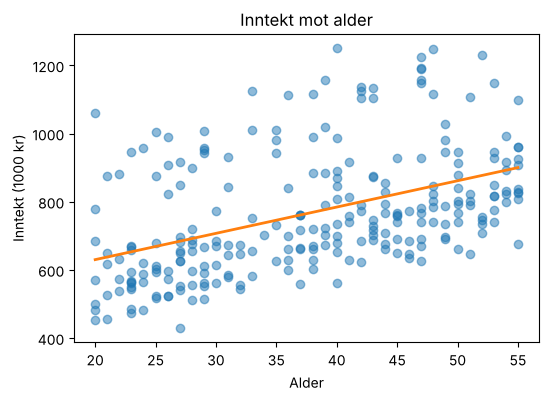

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d2['Alder'], d2['Inntekt']/1000, alpha=0.5)
xs = np.linspace(20, 55, 50)
ax.plot(xs, (m1.params['Intercept'] + m1.params['Alder']*xs)/1000, color='C1', lw=2)
ax.set(xlabel='Alder', ylabel='Inntekt (1000 kr)', title='Inntekt mot alder')
plt.show()

**Svar:** $\widehat{Inntekt} = 475\,776 + 7\,712\cdot Alder$. Ett år eldre gir i snitt ca. 7 700 kr høyere inntekt.

### c) Multippel regresjon: $Inntekt = \beta_0 + \beta_1\,Alder + \beta_2\,Matbudsjett$

In [7]:
m2 = smf.ols('Inntekt ~ Alder + Matbudsjett', data=d2).fit()
display(pd.DataFrame({'koef': m2.params, 'std.feil': m2.bse, 't': m2.tvalues, 'p': m2.pvalues}).round(4))
print(f"Inntekt = {m2.params['Intercept']:.2f} + {m2.params['Alder']:.2f} * Alder + {m2.params['Matbudsjett']:.2f} * Matbudsjett")
print(f"R^2 = {m2.rsquared:.3f}")

,koef,std.feil,t,p
Intercept,451857.5138,37142.4038,12.1655,0.0000
Alder,6717.8551,968.5816,6.9358,0.0000
Matbudsjett,7.2223,1.8966,3.8079,0.0002


Inntekt = 451857.51 + 6717.86 * Alder + 7.22 * Matbudsjett
R^2 = 0.251


**Svar:** $\widehat{Inntekt} = 451\,858 + 6\,718\cdot Alder + 7{,}22\cdot Matbudsjett$.

Alderskoeffisienten synker fra 7 712 til 6 718 når vi kontrollerer for matbudsjett: eldre personer har også større matbudsjett
($r=0{,}27$), så noe av «alderseffekten» i den enkle modellen fanget egentlig opp matbudsjettet.

---
# Oppgave 3 (sek 4.3 og 4.4 H23) – Arkitektlønn

### Korrelasjonsdelen (krever korrelasjonsmatrisen/datasettet)
Korrelasjonsmatrisen «over» er ikke med i PDF-en. Med datasettet blir svaret slik:

In [8]:
filbane3 = 'data/arkitekter.csv'   # <-- endre til riktig fil

if os.path.exists(filbane3):
    d3 = pd.read_csv(filbane3)
    R3 = d3[['Kjønn', 'Lønn', 'Ansiennitet', 'Alder', 'Lønnsgruppe']].corr().round(3)
    display(R3)
    r_l = R3['Lønn'].drop('Lønn');  print("Sterkest med Lønn:", r_l.abs().idxmax())
    r_k = R3['Kjønn'].drop('Kjønn'); print("Svakest med Kjønn:", r_k.abs().idxmin())
else:
    print("Datafilen finnes ikke – sett riktig filbane i filbane3.")

Datafilen finnes ikke – sett riktig filbane i filbane3.


### Regresjonsdelen (Excel-utskrift)

$$\widehat{Lønn} = -368\,998{,}86 - 26\,030{,}553\cdot Kjønn - 33\,187{,}098\cdot Ansiennitet + 38\,891{,}5635\cdot Alder$$

* **Forklaringsgrad:** $R^2 = 0{,}4396 \approx 0{,}44$.
* **40 år vs. 30 år, samme kjønn og ansiennitet:** Alt annet er likt, så forskjellen er
  $\hat\beta_{Alder}\cdot(40-30) = 38\,891{,}56 \cdot 10 \approx 388\,916$ kr.
* **Dummy-variabel:** *Kjønn* (svar **1**) – den tar bare verdiene 1 (mann) og 2 (kvinne).

*Tolkning av Kjønn:* Å gå fra 1 til 2 (mann → kvinne) gir $-26\,031$ kr, alt annet likt.
Det negative fortegnet på ansiennitet skyldes trolig at alder og ansiennitet er sterkt korrelerte (multikollinearitet).

In [9]:
b = {'konst': -368998.86, 'Kjønn': -26030.553, 'Ansiennitet': -33187.098, 'Alder': 38891.5635}
print("R^2 =", round(0.43955264, 2))

def lonn(kjonn, ans, alder):
    return b['konst'] + b['Kjønn']*kjonn + b['Ansiennitet']*ans + b['Alder']*alder

# Ansienniteten (her 5 år) og kjønn (2 = kvinne) faller bort i differansen
diff = lonn(2, 5, 40) - lonn(2, 5, 30)
print(f"Lønnsforskjell 40 vs 30 år: {diff:,.1f} kr")
print("Dummy-variabel: 1 (Kjønn)")

R^2 = 0.44
Lønnsforskjell 40 vs 30 år: 388,915.6 kr
Dummy-variabel: 1 (Kjønn)


---
# Oppgave 4 (sek 3.3 og 3.4 H23, åpen) – Bachelor- og masterkarakter

In [10]:
d4 = pd.read_csv('data/Datasett_eksamen_h23.csv', sep=';', decimal=',')
print(d4.shape)
d4.head()

(230, 10)


,Kjonn,Alder,Landsdel,Opptak,Kartlegging,Forkurs,Studietid,Jobbtid,Bachelor,Master
0,1,23,5,4.24,74.47,78.57,25.39,14.43,3.05,3
1,0,20,1,2.66,25.43,79.26,24.55,18.26,2.40,4
2,0,21,1,3.64,89.52,94.95,28.73,19.28,3.46,2
3,1,20,5,5.59,82.28,70.88,30.88,0.00,3.33,4
4,0,25,5,2.77,57.63,59.86,27.06,7.61,3.30,3


In [3]:
url = 'https://raw.githubusercontent.com/uit-bed-2501/uit-bed-2501/main/data/Datasett_eksamen_h23.csv'
d4 = pd.read_csv(url, sep=';', decimal=',')

print(d4.shape)
d4.head()

(230, 10)


,Kjonn,Alder,Landsdel,Opptak,Kartlegging,Forkurs,Studietid,Jobbtid,Bachelor,Master
0,1,23,5,4.24,74.47,78.57,25.39,14.43,3.05,3
1,0,20,1,2.66,25.43,79.26,24.55,18.26,2.40,4
2,0,21,1,3.64,89.52,94.95,28.73,19.28,3.46,2
3,1,20,5,5.59,82.28,70.88,30.88,0.00,3.33,4
4,0,25,5,2.77,57.63,59.86,27.06,7.61,3.30,3


### a) Multippel regresjon: $Bachelor = \beta_0 + \beta_1 Opptak + \beta_2 Forkurs + \beta_3 Studietid$

In [11]:
m = smf.ols('Bachelor ~ Opptak + Forkurs + Studietid', data=d4).fit()
display(pd.DataFrame({'koef': m.params, 'std.feil': m.bse, 't': m.tvalues, 'p': m.pvalues}).round(4))
print("Koeffisient Studietid:", round(m.params['Studietid'], 2))
print("R^2:", round(m.rsquared, 2))

,koef,std.feil,t,p
Intercept,0.2365,0.2574,0.9191,0.3590
Opptak,0.1505,0.0612,2.4592,0.0147
Forkurs,0.0076,0.0030,2.5380,0.0118
Studietid,0.0570,0.0049,11.5211,0.0000


Koeffisient Studietid: 0.06
R^2: 0.51


**Svar:** Koeffisienten for *Studietid* er **0,06** (0,0570): én time mer studietid per uke gir i snitt 0,057 høyere
bachelorsnitt, alt annet likt. Forklaringsgraden er $R^2 =$ **0,51**.

### b) Enkel regresjon for Trøndelag (`Landsdel == 2`): $Master = \beta_0 + \beta_1 Bachelor$
Viktig: filtrer **før** regresjonen.

In [12]:
trond = d4[d4['Landsdel'] == 2]
print("Antall studenter fra Trøndelag:", len(trond))

m2 = smf.ols('Master ~ Bachelor', data=trond).fit()
display(pd.DataFrame({'koef': m2.params, 'std.feil': m2.bse, 't': m2.tvalues, 'p': m2.pvalues}).round(4))
print(f"Master = {m2.params['Intercept']:.2f} + {m2.params['Bachelor']:.2f} * Bachelor   (R^2 = {m2.rsquared:.3f})")

Antall studenter fra Trøndelag: 14


,koef,std.feil,t,p
Intercept,2.6642,0.8884,2.9987,0.0111
Bachelor,0.2962,0.2622,1.1297,0.2807


Master = 2.66 + 0.30 * Bachelor   (R^2 = 0.096)


In [13]:
# Sammenligning: uten filtrering får man et annet (feil) svar
m_alle = smf.ols('Master ~ Bachelor', data=d4).fit()
print(f"Alle studenter: Master = {m_alle.params['Intercept']:.2f} + {m_alle.params['Bachelor']:.2f} * Bachelor")

Alle studenter: Master = 1.11 + 0.77 * Bachelor


**Svar:** $\widehat{Master} = 2{,}66 + 0{,}30\cdot Bachelor$.

Merk at utvalget bare er 14 studenter, og stigningstallet er ikke signifikant ($p = 0{,}28$) – estimatet er usikkert.

---
# Oppgave 22.4 – Selvstudium og PISA-poeng ($n=27$, $n-2=25$ fg)

| | Estimate | Std. Error | t | p |
|---|---|---|---|---|
| (Intercept) | 498,058 | 38,212 | 13,034 | 0,000 |
| Timer | 1,528 | 2,159 | 0,708 | 0,486 |

**a)** $\hat y = 498{,}058 + 1{,}528\,x$

**b)** $\hat\beta_0 = 498{,}1$ er forventet PISA-poengsum for en elev som bruker **0 timer** på selvstudium.
Dette gir mening bare hvis $x=0$ finnes i datamaterialet (ellers er det ekstrapolering).

**c)** 95 % KI for $\beta_0$: $498{,}058 \pm t_{0{,}025;25}\cdot 38{,}212$, med $t_{0{,}025;25}=2{,}060$.

**d)** 90 % KI for $\beta_1$: $1{,}528 \pm t_{0{,}05;25}\cdot 2{,}159$, med $t_{0{,}05;25}=1{,}708$.

**e)** $H_0:\beta_0=550$ mot $H_1:\beta_0\neq550$: $\;t=\dfrac{498{,}058-550}{38{,}212}$. Forkast hvis $|t|>t_{0{,}005;25}=2{,}787$.

In [14]:
n, fg = 27, 25
b0, se0 = 498.058, 38.212
b1, se1 = 1.528, 2.159

# c) 95 % KI for beta0
t_c = stats.t.ppf(0.975, fg)
print(f"c) t_0.025,25 = {t_c:.3f}   KI: [{b0 - t_c*se0:.2f}, {b0 + t_c*se0:.2f}]")

# d) 90 % KI for beta1
t_d = stats.t.ppf(0.95, fg)
print(f"d) t_0.05,25  = {t_d:.3f}   KI: [{b1 - t_d*se1:.3f}, {b1 + t_d*se1:.3f}]")

# e) Tosidig test, alpha = 0.01
t_obs = (b0 - 550) / se0
t_krit = stats.t.ppf(0.995, fg)
p = 2 * stats.t.sf(abs(t_obs), fg)
print(f"e) t = {t_obs:.3f}, kritisk verdi ±{t_krit:.3f}, p-verdi = {p:.3f}")
print("   Forkast H0" if abs(t_obs) > t_krit else "   Beholder H0")

c) t_0.025,25 = 2.060   KI: [419.36, 576.76]
d) t_0.05,25  = 1.708   KI: [-2.160, 5.216]
e) t = -1.359, kritisk verdi ±2.787, p-verdi = 0.186
   Beholder H0


**Konklusjon:** c) $[419{,}4;\ 576{,}8]$. d) $[-2{,}16;\ 5{,}22]$ – inneholder 0, så selvstudium har ingen signifikant effekt.
e) $t=-1{,}36$, $|t|<2{,}787$ og $p=0{,}186>0{,}01$: vi beholder $H_0$. (Samme svar: 550 ligger inne i KI-et fra c.)

---
# Oppgave 22.5 – Oppmøte og eksamensresultat ($n=100$, $98$ fg, $s_e=21{,}89$)

| | Estimate | Std. Error | t | p |
|---|---|---|---|---|
| (Intercept) | 37,378 | 8,401 | ? | 0,000 |
| Oppmøte | 2,906 | 1,189 | 2,444 | 0,016 |

**a)** $t = 37{,}378/8{,}401$.
**b)** 99 % KI for $\beta_0$ med $t_{0{,}005;98}$.  **c)** 90 % KI for $\beta_1$ med $t_{0{,}05;98}$.

**d)** Ja, hvis $\beta_1\ne0$. Hypoteser: $H_0:\beta_1=0$ mot $H_1:\beta_1\neq 0$
(eller ensidig $H_1:\beta_1>0$ hvis vi på forhånd tror oppmøte hjelper).

**e)** $t=2{,}444$, $p=0{,}016<0{,}05$ → forkast $H_0$.

**f)** $H_0:\beta_0=40$ mot $H_A:\beta_0<40$: $t=(37{,}378-40)/8{,}401$, forkast hvis $t<-t_{0{,}10;98}$.

**g)** $\hat y = 37{,}378+2{,}906\cdot 8$.

**h)** Prediksjonsintervall. Vi trenger $S_{xx}$, som vi finner fra $SE(\hat\beta_1)=s_e/\sqrt{S_{xx}}$:
$$S_{xx}=\left(\frac{s_e}{SE(\hat\beta_1)}\right)^2=\left(\frac{21{,}89}{1{,}189}\right)^2\approx 338{,}9$$

In [15]:
n, fg, se = 100, 98, 21.89
b0, se0 = 37.378, 8.401
b1, se1 = 2.906, 1.189

# a)
print(f"a) t = {b0/se0:.3f}")

# b) 99 % KI beta0
t99 = stats.t.ppf(0.995, fg)
print(f"b) t_0.005,98 = {t99:.3f}  KI: [{b0 - t99*se0:.2f}, {b0 + t99*se0:.2f}]")

# c) 90 % KI beta1
t90 = stats.t.ppf(0.95, fg)
print(f"c) t_0.05,98  = {t90:.3f}  KI: [{b1 - t90*se1:.3f}, {b1 + t90*se1:.3f}]")

# e) tosidig test beta1 = 0
t_e = b1/se1
print(f"e) t = {t_e:.3f}, p = {2*stats.t.sf(t_e, fg):.4f}, kritisk ±{stats.t.ppf(0.975, fg):.3f}")

# f) venstresidig test beta0 = 40, alpha = 0.10
t_f = (b0 - 40)/se0
print(f"f) t = {t_f:.3f}, kritisk {stats.t.ppf(0.10, fg):.3f}, p = {stats.t.cdf(t_f, fg):.3f}")

# g) prediksjon for x = 8
x0 = 8
y0 = b0 + b1*x0
print(f"g) y-hatt = {y0:.2f} %")

# h) 95 % prediksjonsintervall
xbar = 6.82
Sxx = (se/se1)**2
se_pred = se*np.sqrt(1 + 1/n + (x0 - xbar)**2/Sxx)
t95 = stats.t.ppf(0.975, fg)
print(f"h) Sxx = {Sxx:.1f}, SE(pred) = {se_pred:.2f}, PI: [{y0 - t95*se_pred:.1f}, {y0 + t95*se_pred:.1f}]")

a) t = 4.449
b) t_0.005,98 = 2.627  KI: [15.31, 59.45]
c) t_0.05,98  = 1.661  KI: [0.932, 4.880]
e) t = 2.444, p = 0.0163, kritisk ±1.984
f) t = -0.312, kritisk -1.290, p = 0.378
g) y-hatt = 60.63 %
h) Sxx = 338.9, SE(pred) = 22.04, PI: [16.9, 104.4]


**Svar:** a) $t=4{,}45$. b) $[15{,}31;\ 59{,}45]$. c) $[0{,}93;\ 4{,}88]$.
e) Forkast $H_0$: oppmøte har en signifikant (positiv) effekt; hver ekstra forelesning gir ca. 2,9 prosentpoeng mer.
f) $t=-0{,}31 > -1{,}29$: beholder $H_0$. g) $\hat y\approx 60{,}6$ %.
h) $[16{,}9;\ 104{,}4]$ – svært bredt. Intervallet går over 100 %, noe som viser at modellen sier lite om én enkelt student.

---
# Oppgave 22.6 – Markedsføring og publikumstall ($n=7$)

Her har vi rådata, så vi bruker Python som **dataverktøy**. Først for hånd (formler), så med `statsmodels` som kontroll.

In [16]:
film = pd.DataFrame({
    'budsjett': [2.7, 4.4, 2.3, 7.2, 4.7, 2.4, 5.0],
    'publikum': [0.8, 1.1, 0.5, 1.8, 1.1, 0.4, 0.7]}, index=range(1, 8))

x, y = film['budsjett'], film['publikum']
n = len(film)

# Estimater fra formlene
Sxx = ((x - x.mean())**2).sum()
Sxy = ((x - x.mean())*(y - y.mean())).sum()
b1 = Sxy/Sxx
b0 = y.mean() - b1*x.mean()
print(f"x-strek = {x.mean():.3f}, y-strek = {y.mean():.4f}, Sxx = {Sxx:.2f}, Sxy = {Sxy:.3f}")
print(f"b1 = {b1:.4f}, b0 = {b0:.4f}   (oppgaven: -0.059 + 0.237*budsjett)")

x-strek = 4.100, y-strek = 0.9143, Sxx = 18.96, Sxy = 4.500
b1 = 0.2373, b0 = -0.0588   (oppgaven: -0.059 + 0.237*budsjett)


In [17]:
# a) og b) Prognoser og residualer med likningen fra oppgaven
film['y_hatt'] = -0.059 + 0.237*film['budsjett']
film['residual'] = film['publikum'] - film['y_hatt']
film['residual^2'] = film['residual']**2
display(film.round(4))

# c) Regresjonens standardfeil
SSE = film['residual^2'].sum()
s_e = np.sqrt(SSE/(n - 2))
print(f"c) SSE = {SSE:.4f},  s_e = sqrt(SSE/(n-2)) = {s_e:.4f}")

# d) Standardfeilen til stigningstallet
print(f"d) SE(b1) = s_e/sqrt(Sxx) = {s_e/np.sqrt(Sxx):.4f}")

,budsjett,publikum,y_hatt,residual,residual^2
1,2.7,0.8,0.5809,0.2191,0.0480
2,4.4,1.1,0.9838,0.1162,0.0135
3,2.3,0.5,0.4861,0.0139,0.0002
4,7.2,1.8,1.6474,0.1526,0.0233
5,4.7,1.1,1.0549,0.0451,0.0020
6,2.4,0.4,0.5098,-0.1098,0.0121
7,5.0,0.7,1.1260,-0.4260,0.1815


c) SSE = 0.2806,  s_e = sqrt(SSE/(n-2)) = 0.2369
d) SE(b1) = s_e/sqrt(Sxx) = 0.0544


In [18]:
# Kontroll med statsmodels
modell = smf.ols('publikum ~ budsjett', data=film).fit()
display(pd.DataFrame({'koef': modell.params, 'std.feil': modell.bse,
                     't': modell.tvalues, 'p': modell.pvalues}).round(4))
print("s_e =", round(np.sqrt(modell.scale), 4))

,koef,std.feil,t,p
Intercept,-0.0588,0.2403,-0.2447,0.8164
budsjett,0.2373,0.0544,4.3630,0.0073


s_e = 0.2369


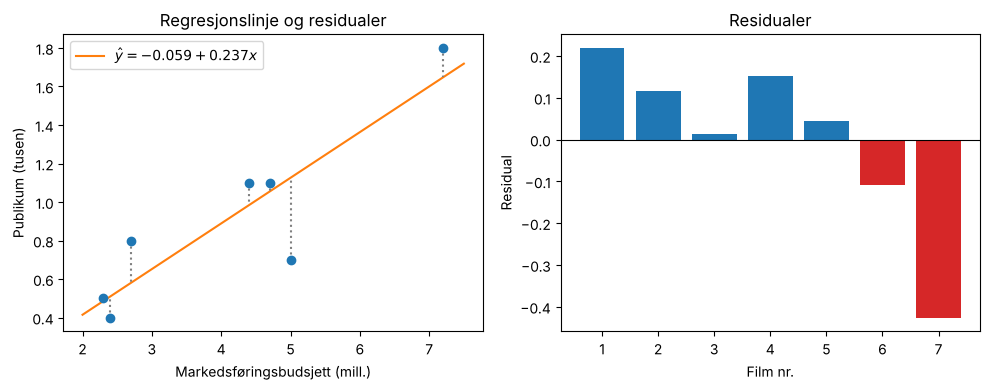

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
xs = np.linspace(2, 7.5, 50)
ax[0].scatter(x, y, color='C0', zorder=3)
ax[0].plot(xs, -0.059 + 0.237*xs, color='C1', label=r'$\hat y=-0.059+0.237x$')
for xi, yi, yh in zip(x, y, film['y_hatt']):
    ax[0].plot([xi, xi], [yi, yh], color='gray', ls=':')
ax[0].set(xlabel='Markedsføringsbudsjett (mill.)', ylabel='Publikum (tusen)', title='Regresjonslinje og residualer')
ax[0].legend()
ax[1].bar(film.index, film['residual'], color=np.where(film['residual'] > 0, 'C0', 'C3'))
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set(xlabel='Film nr.', ylabel='Residual', title='Residualer')
plt.tight_layout(); plt.show()

**Svar:** c) $s_e\approx 0{,}237$. d) $SE(\hat\beta_1)\approx 0{,}0544$.
Film 7 har størst (negativ) residual: den fikk 426 000 færre besøkende enn modellen forventer.

---
# Oppgave 22.7 – Røyking og fødselsvekt ($n=1388$, $1386$ fg)

| Term | Estimate | Std Error | t Ratio | Prob>\|t\| |
|---|---|---|---|---|
| Intercept | 3395,5334 | 16,22586 | 209,27 | <,0001 |
| Sigg | −14,56544 | 2,565418 | −5,68 | <,0001 |

**a)** $\widehat{Fødselsvekt} = 3395{,}53 - 14{,}57\cdot Sigg$

**b)** $\hat\beta_0$: forventet fødselsvekt (ca. 3396 g) når mor ikke røyker.
$\hat\beta_1$: for hver ekstra sigarett per dag synker forventet fødselsvekt med ca. 14,6 g.

**c)** 99 % KI: $-14{,}565 \pm t_{0{,}005;1386}\cdot 2{,}565$. Med så mange frihetsgrader er $t\approx z = 2{,}576$.

**d)** $H_0:\beta_1=0$ mot $H_1:\beta_1<0$, $\alpha=0{,}05$: forkast hvis $t<-t_{0{,}05;1386}\approx-1{,}646$.

In [20]:
fg = 1386
b1, se1 = -14.56544, 2.565418

t99 = stats.t.ppf(0.995, fg)
print(f"c) t_0.005 = {t99:.3f} (z = {stats.norm.ppf(0.995):.3f})")
print(f"   99 % KI: [{b1 - t99*se1:.2f}, {b1 + t99*se1:.2f}]")

t_obs = b1/se1
t_krit = stats.t.ppf(0.05, fg)
print(f"d) t = {t_obs:.2f}, kritisk verdi = {t_krit:.3f}, p (venstresidig) = {stats.t.cdf(t_obs, fg):.1e}")
print("   Forkast H0" if t_obs < t_krit else "   Beholder H0")

# Illustrasjon: 10 sigaretter per dag
print(f"\nEksempel: 10 sigg/dag -> {3395.5334 + b1*10:.0f} g (vs {3395.5334:.0f} g)")

c) t_0.005 = 2.579 (z = 2.576)
   99 % KI: [-21.18, -7.95]
d) t = -5.68, kritisk verdi = -1.646, p (venstresidig) = 8.3e-09
   Forkast H0

Eksempel: 10 sigg/dag -> 3250 g (vs 3396 g)


**e) Konklusjon i klartekst:** Det er sterke holdepunkter for at barn av mødre som røyker under svangerskapet
i gjennomsnitt veier mindre ved fødselen – omtrent 8 til 21 gram mindre per sigarett per dag (99 % KI).
Det er en statistisk sammenheng i observasjonsdata; andre forhold kan også spille inn.